Train shape: (10000, 9)
Test shape: (3320, 8)

Data types:
id                int64
area_type        object
availability     object
location         object
size             object
total_sqft      float64
bath            float64
balcony         float64
price           float64
dtype: object

Numeric columns: ['id', 'total_sqft', 'bath', 'balcony', 'price']
Categorical columns: ['area_type', 'availability', 'location', 'size']

Descriptive Statistics:
              count         mean          std  min      25%     50%      75%  \
id          10000.0  4999.500000  2886.895680  0.0  2499.75  4999.5  7499.25   
total_sqft   9967.0  1570.095822  1302.566836  1.0  1100.00  1279.0  1682.50   
bath         9936.0     2.692029     1.274172  1.0     2.00     2.0     3.00   
balcony      9525.0     1.585302     0.814347  0.0     1.00     2.0     2.00   
price       10000.0   113.275879   151.802643  8.0    50.00    72.0   120.00   

                max  
id           9999.0  
total_sqft  52272.0  
b

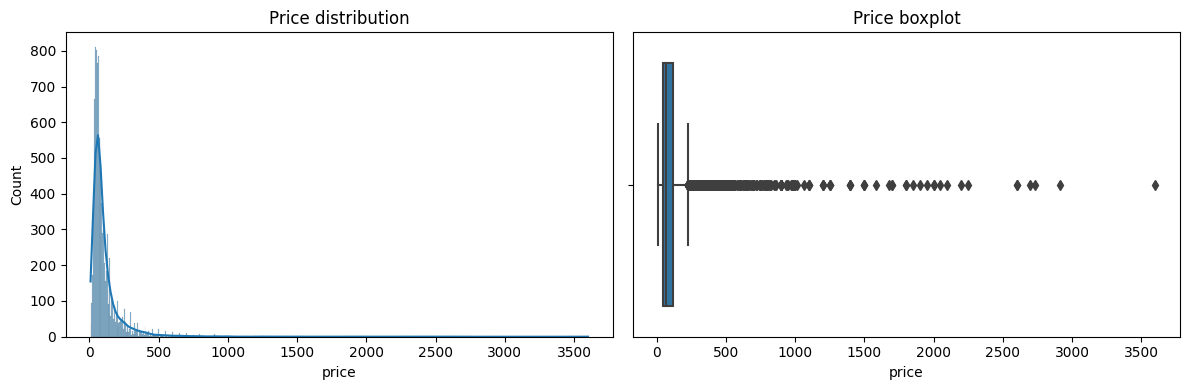


Missing Values Report:
            missing_count  missing_pct
balcony               475         4.75
bath                   64         0.64
total_sqft             33         0.33
size                   13         0.13
location                1         0.01
Decision: imputing categoricals with mode and numerics with median.

Duplicate rows in Train: 0

IQR bounds for total_sqft: [230.0, 2550.0]


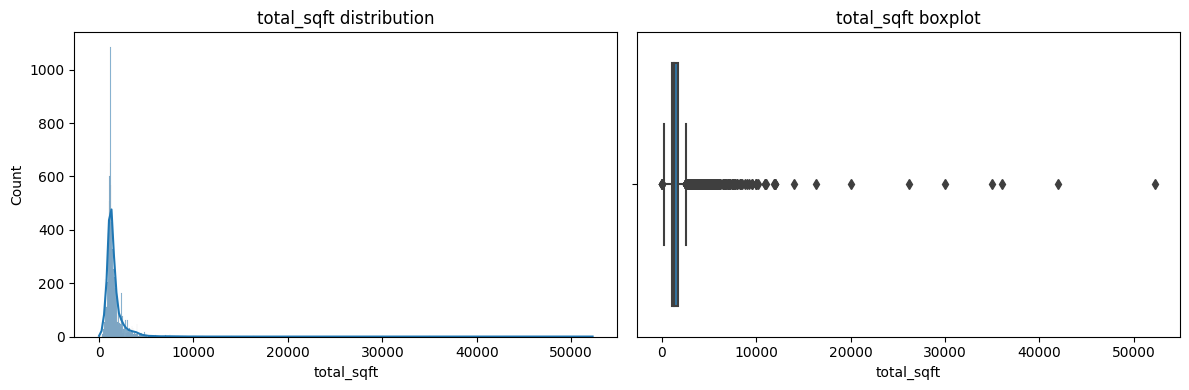


Scaling numeric variables with RobustScaler due to outliers; one-hot encode categoricals with unknown-handling.

Duplicates in final_all_train_input: 0
Duplicates in final_train_input: 0
Duplicates in final_validation_input: 0
Duplicates in final_test_input: 0

=== Creating Visualizations ===


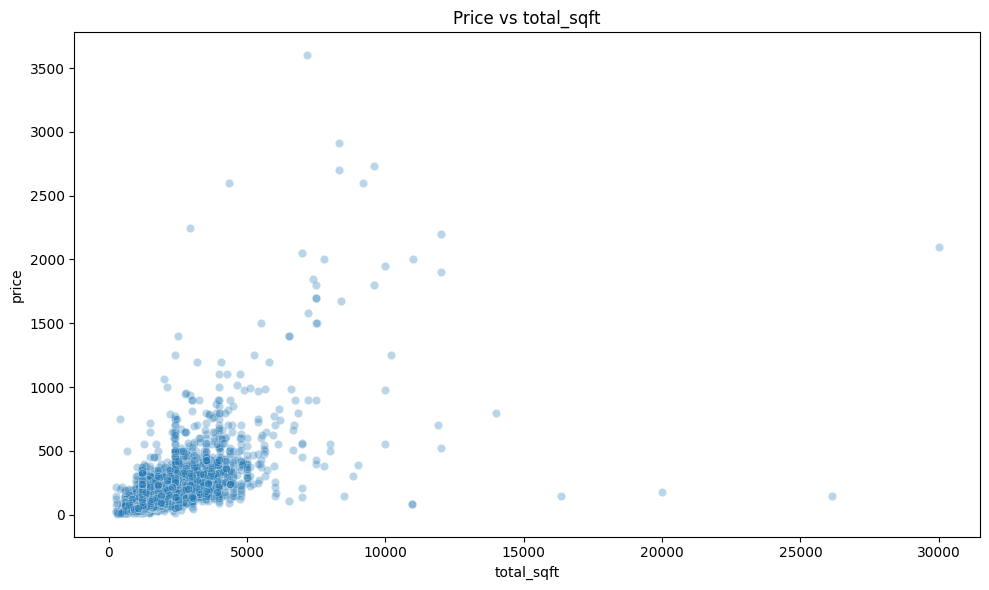

Insight: price increases with sqft; variance widens at higher sqft (heteroscedasticity).


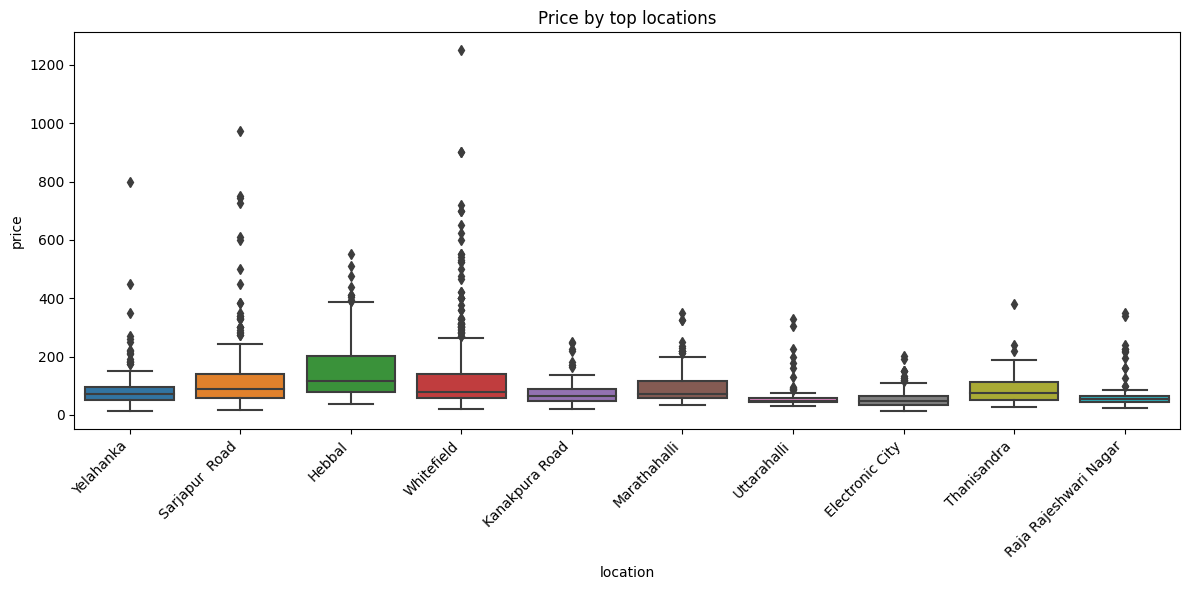

Insight: median prices differ across locations, supporting one-hot encoding.


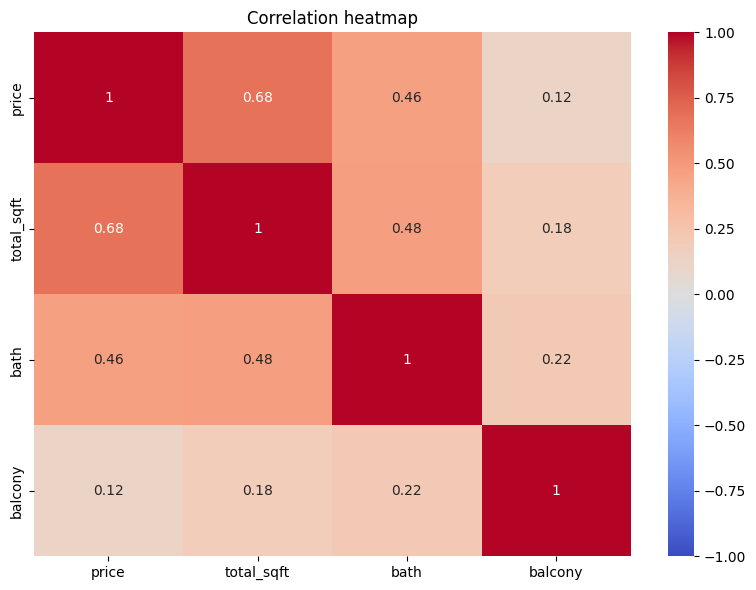

Insight: bath has moderate positive correlation with price; balcony is weaker but informative.

=== Training Models ===
Models: Linear, Ridge, Lasso, DecisionTree, RandomForest, MLP, XGBoost, LightGBM, OLS

[1/9] Training Linear Regression...
Linear Regression Train R²: 0.7187
Linear Regression Validation R²: -340712514949499328.0000

[2/9] Training Ridge Regression...
Ridge Train R²: 0.6984
Ridge Validation R²: 0.6852

[3/9] Training Lasso Regression...
Lasso Train R²: 0.4780
Lasso Validation R²: 0.6767

[4/9] Training Decision Tree...
Decision Tree Train R²: 0.9220
Decision Tree Validation R²: 0.6493

[5/9] Training Random Forest...
Random Forest Train R²: 0.4766
Random Forest Validation R²: 0.4901

[6/9] Training MLP Regressor...
MLP Train R²: 0.9809
MLP Validation R²: 0.6369

[7/9] Training XGBoost...
XGBoost Train R²: 0.9839
XGBoost Validation R²: 0.9409

[8/9] Training LightGBM...
LightGBM Train R²: 0.7687
LightGBM Validation R²: 0.7816

[9/9] Training OLS Regression...

OLS R-sq

In [1]:
# -- coding: utf-8 --
# notebookaac757863f_memory_optimized.py

import warnings
warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')

import numpy as np
import pandas as pd
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import gc  # Garbage collection

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import statsmodels.api as sm

# =============================================================================
# Data loading
# =============================================================================
Traindf = pd.read_csv("/kaggle/input/mlp-term-3-2025-kaggle-assignment-1/train.csv")
Testdf = pd.read_csv("/kaggle/input/mlp-term-3-2025-kaggle-assignment-1/test.csv")
sample_submission = pd.read_csv("/kaggle/input/mlp-term-3-2025-kaggle-assignment-1/sample_submission.csv")

# =============================================================================
# Rubric: Data types
# =============================================================================
print("Train shape:", Traindf.shape)
print("Test shape:", Testdf.shape)
print("\nData types:")
print(Traindf.dtypes)

num_cols_full = Traindf.select_dtypes(include=["int64","float64"]).columns.tolist()
cat_cols_full = Traindf.select_dtypes(include=["object","category"]).columns.tolist()
print("\nNumeric columns:", num_cols_full)
print("Categorical columns:", cat_cols_full)

# =============================================================================
# Rubric: Descriptive statistics
# =============================================================================
print("\nDescriptive Statistics:")
print(Traindf.select_dtypes(include=["int64","float64"]).describe().T)

# Clean data: replace inf with NaN to avoid seaborn warnings
Traindf_viz = Traindf.replace([np.inf, -np.inf], np.nan)

fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(Traindf_viz["price"], kde=True, ax=ax[0])
sns.boxplot(x=Traindf_viz["price"], ax=ax[1])
ax[0].set_title("Price distribution")
ax[1].set_title("Price boxplot")
plt.tight_layout()
plt.show()

# =============================================================================
# Rubric: Missing values
# =============================================================================
missing_cnt = Traindf.isna().sum().sort_values(ascending=False)
missing_pct = (Traindf.isna().mean()*100).sort_values(ascending=False)
mv_report = pd.DataFrame({"missing_count": missing_cnt, "missing_pct": missing_pct})
print("\nMissing Values Report:")
print(mv_report[mv_report.missing_count>0])
print("Decision: imputing categoricals with mode and numerics with median.")

# =============================================================================
# Imputation
# =============================================================================
mode_imputer = SimpleImputer(strategy="most_frequent")
median_imputer = SimpleImputer(strategy="median")
cat_cols = ["location","size","bath","balcony"]
num_cols = ["total_sqft"]

preprocessor = ColumnTransformer(transformers=[
    ("mode_imputer" , mode_imputer, cat_cols),
    ("median_imputer" , median_imputer , num_cols)
])
imputer_pipeline = Pipeline(steps=[("imputation",preprocessor)])
imputer_pipeline.fit(Traindf[cat_cols + num_cols])

Traindf_imputed = pd.DataFrame(imputer_pipeline.transform(Traindf[cat_cols + num_cols]), columns=cat_cols + num_cols , index=Traindf.index )
Testdf_imputed = pd.DataFrame(imputer_pipeline.transform(Testdf[cat_cols + num_cols]), columns=cat_cols + num_cols, index=Testdf.index )
Traindf[cat_cols + num_cols] = Traindf_imputed
Testdf[cat_cols + num_cols] = Testdf_imputed
Traindf[["bath","balcony"]] = Traindf[["bath","balcony"]].astype(int)
Traindf["total_sqft"] = Traindf["total_sqft"].astype(int)
Testdf[["bath","balcony"]] = Testdf[["bath","balcony"]].astype(int)
Testdf["total_sqft"] = Testdf["total_sqft"].astype(int)

# =============================================================================
# Rubric: Duplicates
# =============================================================================
dup_ct = Traindf.duplicated().sum()
print(f"\nDuplicate rows in Train: {dup_ct}")
if dup_ct>0:
    Traindf = Traindf.drop_duplicates().reset_index(drop=True)
    print("Dropped exact duplicate rows.")

# =============================================================================
# Rubric: Outliers (IQR)
# =============================================================================
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

lb, ub = iqr_bounds(Traindf["total_sqft"], k=1.5)
print(f"\nIQR bounds for total_sqft: [{lb:.1f}, {ub:.1f}]")

# Clean data for visualization
Traindf_viz = Traindf.replace([np.inf, -np.inf], np.nan)

fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(Traindf_viz["total_sqft"], kde=True, ax=ax[0])
sns.boxplot(x=Traindf_viz["total_sqft"], ax=ax[1])
ax[0].set_title("total_sqft distribution")
ax[1].set_title("total_sqft boxplot")
plt.tight_layout()
plt.show()

# Your rules
Traindf.loc[Traindf["total_sqft"] < 250 , "total_sqft" ] = 250
Testdf.loc[Testdf["total_sqft"] < 250 , "total_sqft"] = 250
Traindf.drop(Traindf[Traindf["total_sqft"] > 30000].index, inplace=True)

# =============================================================================
# Train/validation split
# =============================================================================
train , validation = train_test_split(Traindf ,test_size=0.2, random_state=42)
model_input = Testdf.columns.tolist()[1:]
train_input = train[model_input]
train_output = train["price"]
validation_input = validation[model_input]
validation_output = validation["price"]

# =============================================================================
# Rubric: Scaling and encoding
# =============================================================================
print("\nScaling numeric variables with RobustScaler due to outliers; one-hot encode categoricals with unknown-handling.")
scaler = RobustScaler()
hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
numeric_columns = ["total_sqft" , "bath" ,"balcony"]
categorical_column = ["area_type","availability" , "location" , "size"]
processor = ColumnTransformer(transformers=[
    ("scaler", scaler , numeric_columns ),
    ("encoder",hot_encoder , categorical_column)
] , remainder="passthrough")
hot_scale = Pipeline(steps=[("scale_and_encode" , processor)])
hot_scale.fit(train_input)

final_train_input = pd.DataFrame(
    hot_scale.transform(train_input),
    columns=hot_scale.named_steps["scale_and_encode"].get_feature_names_out()
)
final_validation_input = pd.DataFrame(
    hot_scale.transform(validation_input),
    columns=hot_scale.named_steps["scale_and_encode"].get_feature_names_out()
)

all_train_input = Traindf[model_input]
all_train_output = Traindf["price"]
hot_scale.fit(all_train_input)
final_all_train_input = pd.DataFrame(
    hot_scale.transform(all_train_input),
    columns=hot_scale.named_steps["scale_and_encode"].get_feature_names_out()
)
final_test_input = pd.DataFrame(
    hot_scale.transform(Testdf[model_input]),
    columns=hot_scale.named_steps["scale_and_encode"].get_feature_names_out()
)

# Remove duplicate columns if any
def remove_duplicate_columns(df):
    _, idx = np.unique(df.columns, return_index=True)
    return df.iloc[:, idx]

final_all_train_input = remove_duplicate_columns(final_all_train_input)
final_validation_input = remove_duplicate_columns(final_validation_input)
final_test_input = remove_duplicate_columns(final_test_input)
final_train_input = remove_duplicate_columns(final_train_input)

# Align columns
train_cols = final_all_train_input.columns
final_validation_input = final_validation_input.reindex(columns=train_cols, fill_value=0)
final_test_input = final_test_input.reindex(columns=train_cols, fill_value=0)
final_train_input = final_train_input.reindex(columns=train_cols, fill_value=0)

# Clean special characters for LightGBM
def clean_column_names(df):
    df.columns = [re.sub(r'[^A-Za-z0-9_]+', '', col) for col in df.columns]
    return df

final_all_train_input = clean_column_names(final_all_train_input)
final_validation_input = clean_column_names(final_validation_input)
final_test_input = clean_column_names(final_test_input)
final_train_input = clean_column_names(final_train_input)

# Make column names unique
def make_columns_unique(df):
    cols = df.columns.tolist()
    seen = {}
    new_cols = []
    for col in cols:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

final_all_train_input = make_columns_unique(final_all_train_input)
final_validation_input = make_columns_unique(final_validation_input)
final_test_input = make_columns_unique(final_test_input)
final_train_input = make_columns_unique(final_train_input)

# Re-align after uniqueness
train_cols = final_all_train_input.columns
final_validation_input = final_validation_input.reindex(columns=train_cols, fill_value=0)
final_test_input = final_test_input.reindex(columns=train_cols, fill_value=0)
final_train_input = final_train_input.reindex(columns=train_cols, fill_value=0)

# Verify no duplicates
print(f"\nDuplicates in final_all_train_input: {final_all_train_input.columns.duplicated().sum()}")
print(f"Duplicates in final_train_input: {final_train_input.columns.duplicated().sum()}")
print(f"Duplicates in final_validation_input: {final_validation_input.columns.duplicated().sum()}")
print(f"Duplicates in final_test_input: {final_test_input.columns.duplicated().sum()}")

# =============================================================================
# Rubric: ≥3 Visualizations with insights
# =============================================================================
print("\n=== Creating Visualizations ===")

# Clean data: replace inf with NaN to avoid warnings
Traindf_clean = Traindf.replace([np.inf, -np.inf], np.nan)

# 1) Price vs total_sqft
plt.figure(figsize=(10, 6))
sns.scatterplot(data=Traindf_clean, x="total_sqft", y="price", alpha=0.3)
plt.title("Price vs total_sqft")
plt.tight_layout()
plt.show()
print("Insight: price increases with sqft; variance widens at higher sqft (heteroscedasticity).")

# 2) Price by location (top 10)
top_locs = Traindf_clean["location"].value_counts().head(10).index
plt.figure(figsize=(12, 6))
sns.boxplot(data=Traindf_clean[Traindf_clean["location"].isin(top_locs)], x="location", y="price")
plt.xticks(rotation=45, ha="right")
plt.title("Price by top locations")
plt.tight_layout()
plt.show()
print("Insight: median prices differ across locations, supporting one-hot encoding.")

# 3) Correlation heatmap
plt.figure(figsize=(8, 6))
corr = Traindf_clean[["price","total_sqft","bath","balcony"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()
print("Insight: bath has moderate positive correlation with price; balcony is weaker but informative.")

# =============================================================================
# Modeling (≥7 models) - MEMORY OPTIMIZED
# =============================================================================
print("\n=== Training Models ===")
print("Models: Linear, Ridge, Lasso, DecisionTree, RandomForest, MLP, XGBoost, LightGBM, OLS")

# Linear Regression
print("\n[1/9] Training Linear Regression...")
lr_model = LinearRegression(fit_intercept=True, n_jobs=-1)
lr_model.fit(final_train_input , train_output)
print(f"Linear Regression Train R²: {lr_model.score(final_train_input,train_output):.4f}")
print(f"Linear Regression Validation R²: {lr_model.score(final_validation_input , validation_output):.4f}")

# Ridge Regression
print("\n[2/9] Training Ridge Regression...")
ridge_model = Ridge(random_state=42)
ridge_model.fit(final_train_input , train_output)
print(f"Ridge Train R²: {ridge_model.score(final_train_input,train_output):.4f}")
print(f"Ridge Validation R²: {ridge_model.score(final_validation_input , validation_output):.4f}")

# Lasso Regression
print("\n[3/9] Training Lasso Regression...")
lasso_model = Lasso(random_state=42)
lasso_model.fit(final_train_input , train_output)
print(f"Lasso Train R²: {lasso_model.score(final_train_input,train_output):.4f}")
print(f"Lasso Validation R²: {lasso_model.score(final_validation_input , validation_output):.4f}")

# Decision Tree
print("\n[4/9] Training Decision Tree...")
tree_model = DecisionTreeRegressor(max_depth=15, random_state=42)
tree_model.fit(final_train_input , train_output)
print(f"Decision Tree Train R²: {tree_model.score(final_train_input,train_output):.4f}")
print(f"Decision Tree Validation R²: {tree_model.score(final_validation_input , validation_output):.4f}")

# Random Forest
print("\n[5/9] Training Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=1200,
    max_depth=20,
    min_samples_split=3,
    min_samples_leaf=2,
    max_features='sqrt',
    n_jobs=-1,
    random_state=42
)
rf_model.fit(final_train_input, train_output)
print(f"Random Forest Train R²: {rf_model.score(final_train_input,train_output):.4f}")
print(f"Random Forest Validation R²: {rf_model.score(final_validation_input, validation_output):.4f}")

# MLP Regressor (log-target)
print("\n[6/9] Training MLP Regressor...")
y_train_log = np.log1p(train_output)
y_val_log = np.log1p(validation_output)
mlp = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate='adaptive',
    max_iter=1000,
    random_state=42
)
mlp.fit(final_train_input, y_train_log)
mlp_pred_train = np.expm1(mlp.predict(final_train_input))
mlp_pred_val = np.expm1(mlp.predict(final_validation_input))
print(f"MLP Train R²: {r2_score(train_output, mlp_pred_train):.4f}")
print(f"MLP Validation R²: {r2_score(validation_output, mlp_pred_val):.4f}")

# XGBoost
print("\n[7/9] Training XGBoost...")
xgb = XGBRegressor(
    n_estimators=1500,
    max_depth=10,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=0.8,
    min_child_weight=1,
    gamma=0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)
xgb.fit(final_all_train_input, all_train_output)
print(f"XGBoost Train R²: {xgb.score(final_all_train_input,all_train_output):.4f}")
print(f"XGBoost Validation R²: {xgb.score(final_validation_input, validation_output):.4f}")

# LightGBM
print("\n[8/9] Training LightGBM...")
lgbm_model = LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=8,
    num_leaves=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.3,
    reg_lambda=0.5,
    min_child_samples=20,
    min_split_gain=0.1,
    random_state=42,
    verbose=-1
)
lgbm_model.fit(final_all_train_input, all_train_output)
print(f"LightGBM Train R²: {lgbm_model.score(final_all_train_input, all_train_output):.4f}")
print(f"LightGBM Validation R²: {lgbm_model.score(final_validation_input, validation_output):.4f}")

# OLS Regression
print("\n[9/9] Training OLS Regression...")
final_train_input_reset = final_train_input.reset_index(drop=True)
final_validation_input_reset = final_validation_input.reset_index(drop=True)
train_output_reset = train_output.reset_index(drop=True)
validation_output_reset = validation_output.reset_index(drop=True)

ols_train_input = sm.add_constant(final_train_input_reset)
ols_validation_input = sm.add_constant(final_validation_input_reset)
ols_model = sm.OLS(train_output_reset, ols_train_input).fit()
print(f"\nOLS R-squared: {ols_model.rsquared:.4f}")
print(f"OLS Adj. R-squared: {ols_model.rsquared_adj:.4f}")
ols_predictions = ols_model.predict(ols_validation_input)
print(f"OLS Validation R²: {r2_score(validation_output_reset, ols_predictions):.4f}")

# =============================================================================
# Rubric: Hyperparameter tuning - MANUAL APPROACH (Memory Safe)
# =============================================================================
print("\n=== Hyperparameter Tuning (Manual Cross-Validation) ===")
print("Using manual CV to avoid memory issues with GridSearchCV")

cv = KFold(n_splits=3, shuffle=True, random_state=42)

# Ridge - Manual tuning
print("\n[1/3] Tuning Ridge manually...")
ridge_alphas = [0.1, 1.0, 10.0]
ridge_scores = {}
for alpha in ridge_alphas:
    model = Ridge(alpha=alpha, random_state=42)
    scores = cross_val_score(model, final_train_input, train_output, scoring="r2", cv=cv, n_jobs=-1)
    ridge_scores[alpha] = scores.mean()
    print(f"  alpha={alpha}: CV R² = {scores.mean():.4f}")
best_ridge_alpha = max(ridge_scores, key=ridge_scores.get)
print(f"Ridge best alpha: {best_ridge_alpha}, CV R²: {ridge_scores[best_ridge_alpha]:.4f}")
gc.collect()

# RandomForest - Manual tuning (reduced to avoid memory issues)
print("\n[2/3] Tuning RandomForest manually...")
rf_configs = [
    {"n_estimators": 800, "max_depth": 15, "max_features": "sqrt"},
    {"n_estimators": 1200, "max_depth": 20, "max_features": "sqrt"},
]
rf_scores = {}
for i, config in enumerate(rf_configs):
    print(f"  Testing config {i+1}/{len(rf_configs)}: {config}")
    model = RandomForestRegressor(**config, random_state=42, n_jobs=-1)
    scores = cross_val_score(model, final_train_input, train_output, scoring="r2", cv=cv, n_jobs=-1)
    rf_scores[i] = {"config": config, "score": scores.mean()}
    print(f"    CV R² = {scores.mean():.4f}")
    gc.collect()
best_rf_idx = max(rf_scores, key=lambda k: rf_scores[k]["score"])
best_rf_config = rf_scores[best_rf_idx]["config"]
print(f"RF best config: {best_rf_config}, CV R²: {rf_scores[best_rf_idx]['score']:.4f}")

# XGBoost - Manual tuning (reduced to avoid memory issues)
print("\n[3/3] Tuning XGBoost manually...")
xgb_configs = [
    {"n_estimators": 1200, "max_depth": 8, "learning_rate": 0.08},
    {"n_estimators": 1500, "max_depth": 10, "learning_rate": 0.08},
]
xgb_scores = {}
for i, config in enumerate(xgb_configs):
    print(f"  Testing config {i+1}/{len(xgb_configs)}: {config}")
    model = XGBRegressor(**config, subsample=0.85, colsample_bytree=0.85,
                         objective="reg:squarederror", random_state=42, n_jobs=-1)
    scores = cross_val_score(model, final_train_input, train_output, scoring="r2", cv=cv, n_jobs=-1)
    xgb_scores[i] = {"config": config, "score": scores.mean()}
    print(f"    CV R² = {scores.mean():.4f}")
    gc.collect()
best_xgb_idx = max(xgb_scores, key=lambda k: xgb_scores[k]["score"])
best_xgb_config = xgb_scores[best_xgb_idx]["config"]
print(f"XGB best config: {best_xgb_config}, CV R²: {xgb_scores[best_xgb_idx]['score']:.4f}")

# =============================================================================
# Rubric: Comparison of model performances
# =============================================================================
print("\n=== Model Performance Comparison ===")
from collections import OrderedDict
perf = OrderedDict()

perf["Linear"] = {
    "train_r2": lr_model.score(final_train_input, train_output),
    "valid_r2": lr_model.score(final_validation_input, validation_output)
}
perf["Ridge"] = {
    "train_r2": ridge_model.score(final_train_input, train_output),
    "valid_r2": ridge_model.score(final_validation_input, validation_output)
}
perf["Lasso"] = {
    "train_r2": lasso_model.score(final_train_input, train_output),
    "valid_r2": lasso_model.score(final_validation_input, validation_output)
}
perf["DecisionTree"] = {
    "train_r2": tree_model.score(final_train_input, train_output),
    "valid_r2": tree_model.score(final_validation_input, validation_output)
}
perf["RandomForest"] = {
    "train_r2": rf_model.score(final_train_input, train_output),
    "valid_r2": rf_model.score(final_validation_input, validation_output)
}
perf["MLP"] = {
    "train_r2": r2_score(train_output, mlp_pred_train),
    "valid_r2": r2_score(validation_output, mlp_pred_val)
}
perf["XGBoost"] = {
    "train_r2": xgb.score(final_all_train_input, all_train_output),
    "valid_r2": xgb.score(final_validation_input, validation_output)
}
perf["LightGBM"] = {
    "train_r2": lgbm_model.score(final_all_train_input, all_train_output),
    "valid_r2": lgbm_model.score(final_validation_input, validation_output)
}
perf["OLS"] = {
    "train_r2": ols_model.rsquared, 
    "valid_r2": r2_score(validation_output_reset, ols_predictions)
}

perf_df = pd.DataFrame(perf).T.sort_values("valid_r2", ascending=False)
print("\nModel Performance Summary:")
print(perf_df)

best_name = perf_df.index[0]
print(f"\n✓ Best validation model: {best_name} (R²={perf_df.loc[best_name,'valid_r2']:.4f})")

# Optional: 5-fold CV for the best model
print("\n=== Cross-Validation for Best Model ===")
best_est = xgb if best_name == "XGBoost" else (lgbm_model if best_name=="LightGBM" else rf_model)
cv_scores = cross_val_score(best_est, final_all_train_input, all_train_output, scoring="r2", cv=5, n_jobs=-1)
print(f"Best model ({best_name}) 5-fold CV R²: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

# =============================================================================
# Submissions
# =============================================================================
print("\n=== Creating Submissions ===")

# Individual XGB
print("Creating XGBoost submission...")
final_test_prediction = xgb.predict(final_test_input)
sample_submission["price"] = final_test_prediction
sample_submission.to_csv('/kaggle/working/submission.csv', index=False)
print("✓ XGBoost submission saved as 'submission.csv'")

# Ensemble (XGB, LGBM, RF)
print("Creating Ensemble submission...")
xgb_pred = xgb.predict(final_test_input)
lgbm_pred = lgbm_model.predict(final_test_input)
rf_pred = rf_model.predict(final_test_input)
ensemble_pred = 0.5 * xgb_pred + 0.3 * lgbm_pred + 0.2 * rf_pred
sample_submission["price"] = ensemble_pred
sample_submission.to_csv('/kaggle/working/submission_ensemble.csv', index=False)
print("✓ Ensemble submission saved as 'submission_ensemble.csv'")

print("\n=== All Done! ===")